ASSIGNMENT-10

Q1. Write a program to denoise the input image using adaptive median filter.
Input the initial window size and maximum size of window (Smax) from
the user. Compare the performance of median filter and adaptive median filter, using the PSNR values.

Enter image path: /content/img.jpg
Enter initial window size (odd number): 31
Enter maximum window size (odd number): 131
PSNR of Normal Median Filter: 23.58504406473731 dB
PSNR of Adaptive Median Filter: 33.441117000272925 dB


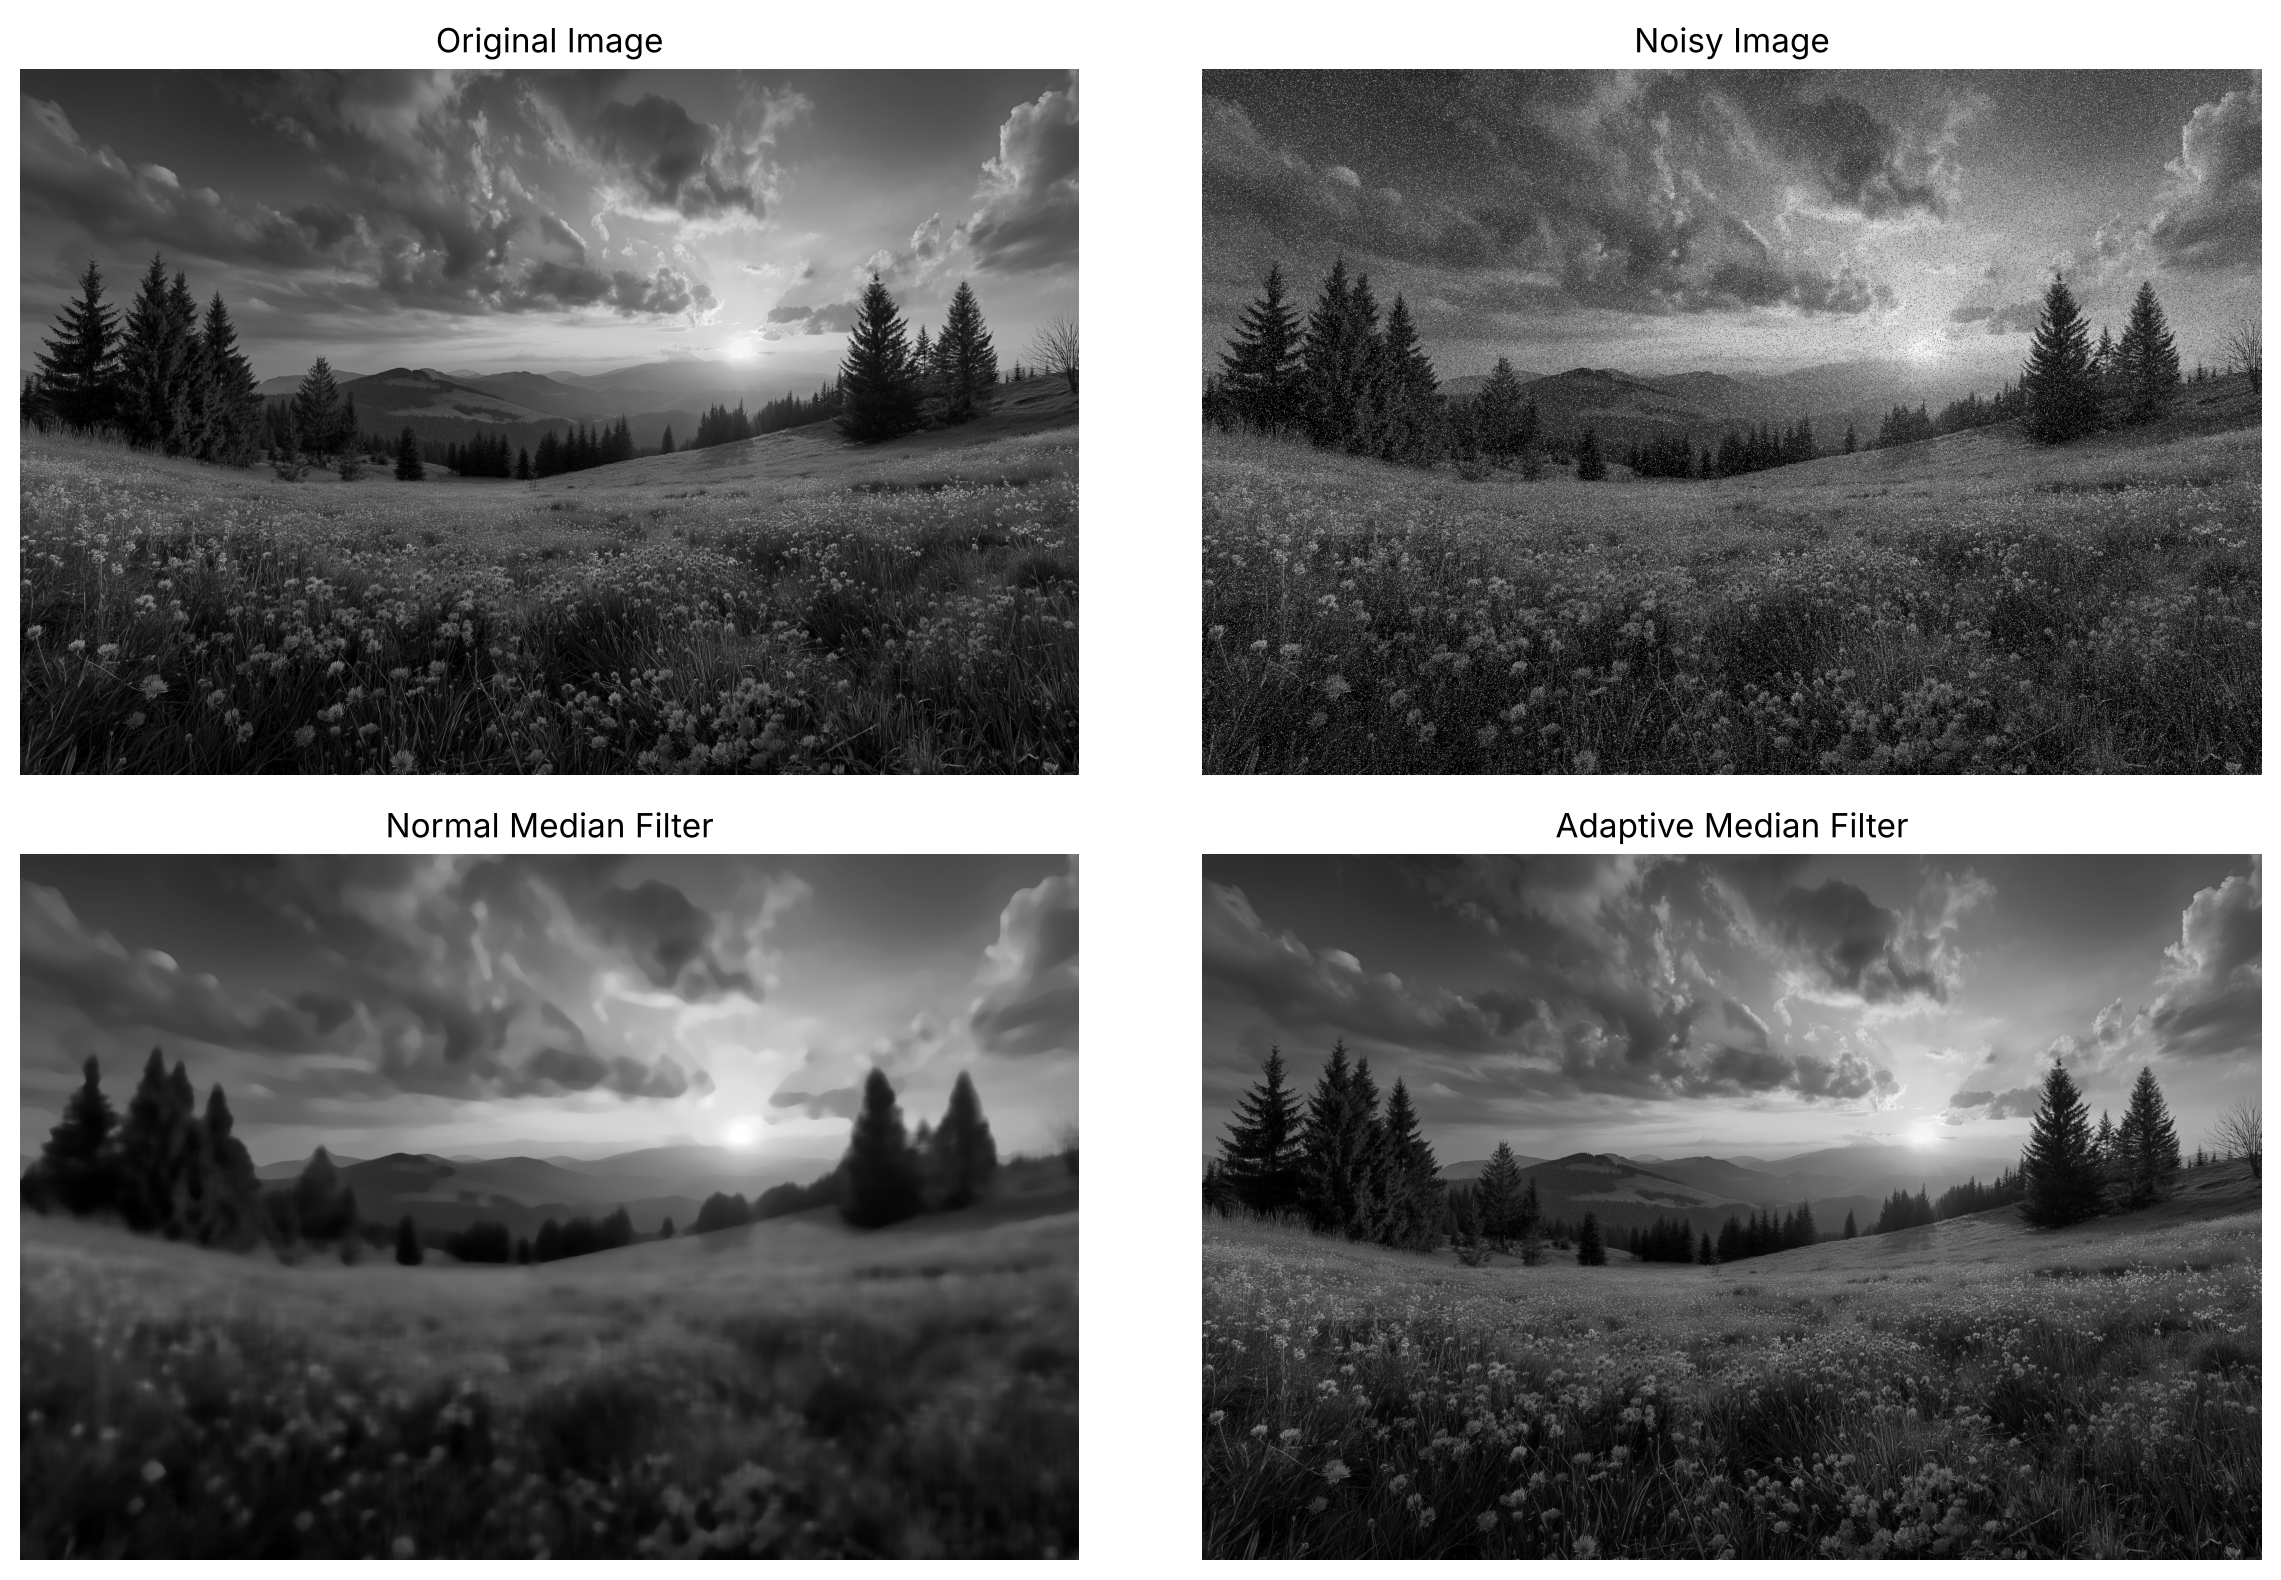

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

path = input("Enter image path: ")
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")

else:
    Smin = int(input("Enter initial window size (odd number): "))
    Smax = int(input("Enter maximum window size (odd number): "))

    if Smin < 3 or Smin % 2 == 0 or Smax % 2 == 0 or Smax < Smin:
        print("Enter valid odd window sizes, with Smax >= Smin.")

    else:
        noisy = img.copy()
        noise = np.random.random(img.shape)

        noisy[noise < 0.05] = 0
        noisy[noise > 0.95] = 255

        # Normal median filter
        median_img = cv2.medianBlur(noisy, Smin)

        # Adaptive median filter
        def adaptive_median(image, Smin, Smax):

            output = image.copy()
            rows, cols = image.shape

            for i in range(rows):
                for j in range(cols):

                    window_size = Smin
                    pixel = image[i, j]

                    while window_size <= Smax:

                        half = window_size // 2

                        r1 = max(0, i-half)
                        r2 = min(rows, i+half+1)
                        c1 = max(0, j-half)
                        c2 = min(cols, j+half+1)

                        window = image[r1:r2, c1:c2]

                        Zmin = np.min(window)
                        Zmax = np.max(window)
                        Zmed = np.median(window)

                        # Stage A
                        if Zmin < Zmed < Zmax:

                            # Stage B
                            if Zmin < pixel < Zmax:
                                output[i, j] = pixel
                            else:
                                output[i, j] = Zmed

                            break

                        else:
                            window_size += 2

                    if window_size > Smax:
                        output[i, j] = Zmed

            return output.astype(np.uint8)

        adaptive_img = adaptive_median(noisy, Smin, Smax)

        # Calculate PSNR
        def calculate_psnr(original, restored):

            mse = np.mean(
                (original.astype(float) -
                 restored.astype(float)) ** 2
            )

            if mse == 0:
                return float('inf')

            return 10 * np.log10((255 ** 2) / mse)

        psnr_median = calculate_psnr(img, median_img)
        psnr_adaptive = calculate_psnr(img, adaptive_img)

        # Print PSNR values
        print("PSNR of Normal Median Filter:",
              psnr_median, "dB")

        print("PSNR of Adaptive Median Filter:",
              psnr_adaptive, "dB")

        # Display results
        plt.figure(figsize=(12, 8))

        images = [
            img, noisy, median_img, adaptive_img
        ]

        titles = [
            "Original Image",
            "Noisy Image",
            "Normal Median Filter",
            "Adaptive Median Filter"
        ]

        for i in range(4):
            plt.subplot(2, 2, i+1)
            plt.imshow(images[i], cmap='gray')
            plt.title(titles[i])
            plt.axis("off")

        plt.tight_layout()
        plt.show()


Q2. Write a program to threshold the image using Otsu's global threshold for segmentation of input gray scale image.

Enter image path: /content/img.jpg
Otsu Threshold Value: 87.0


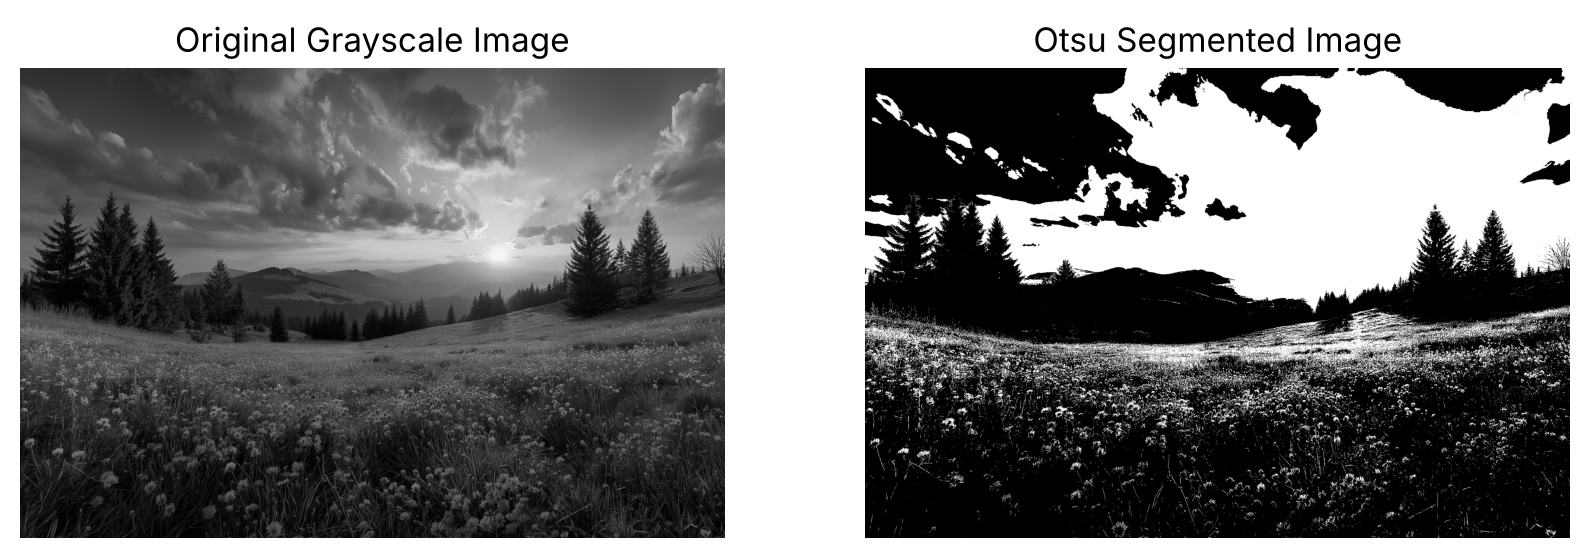

In [2]:
import cv2
import matplotlib.pyplot as plt

# Read input image in grayscale
path = input("Enter image path: ")
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")

else:
    # Apply Otsu's thresholding
    threshold_value, otsu_img = cv2.threshold(
        img,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Print threshold value
    print("Otsu Threshold Value:", threshold_value)

    # Display original and segmented images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Grayscale Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(otsu_img, cmap='gray')
    plt.title("Otsu Segmented Image")
    plt.axis("off")

    plt.show()
